# 2 Modelos y extensión

Responsable: **Izan**. Se parte de la regresión logística y las representaciones
del cuaderno inicial de Mónica. BERT congelado procede de la extracción de Sara.
Aquí se ajustan los clasificadores, se implementa una red propia con PyTorch y
se compara texto con metadatos. El fine-tuning y el análisis conjunto están en el
cuaderno 03 de Sara.

Las decisiones se toman con **validación**, manteniendo las particiones del grupo.
Las predicciones tienen el formato que consume el cuaderno 03. El test queda
desactivado hasta cerrar todas las decisiones; no hace falta para entregar a
Sara esta primera comparación con sus resultados de validación.


In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")

import copy
import hashlib
import importlib.metadata
import json
import platform
import random
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sparse
import torch
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

from funciones import (
    RAIZ, CACHE, RESULTADOS, FIGURAS, SEMILLA, _huella,
    cargar_datos, preparar_datos, cargar_o_crear_particiones,
    preprocesar_resumenes, crear_tfidf, crear_word2vec,
    cargar_representacion, guardar_representacion,
    evaluar, guardar_metricas, guardar_predicciones,
)

torch.set_num_threads(4)
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

EVALUAR_TEST = False
FORZAR_ENTRENAMIENTO = False
VERSION_EXPERIMENTOS = "izan-v1"
ARCHIVO_METRICAS = "metricas_izan.csv"
MODELOS = CACHE / "modelos_izan"
MODELOS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)
RESULTADOS.mkdir(parents=True, exist_ok=True)

versiones = {
    paquete: importlib.metadata.version(paquete)
    for paquete in ["numpy", "pandas", "scipy", "scikit-learn", "spacy", "en-core-web-sm", "gensim", "torch", "joblib", "matplotlib"]
}
versiones["python"] = platform.python_version()
(RESULTADOS / "entorno_izan.json").write_text(
    json.dumps(versiones, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Entorno:", versiones)
print("Test activado:", EVALUAR_TEST)


Entorno: {'numpy': '2.3.5', 'pandas': '3.0.1', 'scipy': '1.18.1', 'scikit-learn': '1.8.0', 'spacy': '3.8.18', 'en-core-web-sm': '3.8.0', 'gensim': '4.4.0', 'torch': '2.11.0+cpu', 'joblib': '1.6.0', 'matplotlib': '3.11.2', 'python': '3.12.14'}
Test activado: False


## Datos y comprobación con los resultados de Sara

Se conservan 60 % train, 30 % validación y 10 % test, con semilla 42 y
estratificación por nivel 2. Cargamos el CSV existente y comprobamos que las
etiquetas e identificadores de validación coinciden con los usados por Sara.
No se modifica el criterio de etiquetas para forzar el porcentaje del enunciado.


In [2]:
projects, scivoc = cargar_datos()
df = preparar_datos(projects, scivoc)
conjuntos = cargar_o_crear_particiones(df)
clases_nivel = {
    nivel: sorted(int(c) for c in conjuntos["train"][f"label_nivel{nivel}"].unique())
    for nivel in (1, 2)
}
for nombre, parte in conjuntos.items():
    print(nombre, len(parte))
print("Clases:", {n: len(c) for n, c in clases_nivel.items()})

for nivel in (1, 2):
    ruta = RESULTADOS / "predicciones" / f"baseline_mayoritaria_n{nivel}_val.csv"
    if ruta.exists():
        sara = pd.read_csv(ruta)
        nuestra = conjuntos["val"][["projectID", f"label_nivel{nivel}"]]
        unidas = nuestra.merge(sara[["projectID", "y_real"]], on="projectID", validate="one_to_one")
        assert len(unidas) == len(nuestra) == len(sara)
        assert (unidas[f"label_nivel{nivel}"] == unidas["y_real"]).all()
        print(f"Nivel {nivel}: mismos {len(unidas)} proyectos y etiquetas que Sara.")

FIRMA_DATOS = {k: _huella(conjuntos[k]) for k in ("train", "val")}
def hash_archivo(ruta):
    calculo = hashlib.sha256()
    with open(ruta, "rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024*1024), b""):
            calculo.update(bloque)
    return calculo.hexdigest()

firma_base = dict(version=VERSION_EXPERIMENTOS, datos=FIRMA_DATOS, entorno=versiones)


train 19189
val 9594
test 3199
Clases: {1: 6, 2: 39}
Nivel 1: mismos 9594 proyectos y etiquetas que Sara.
Nivel 2: mismos 9594 proyectos y etiquetas que Sara.


## Representaciones

Si TF-IDF y Word2Vec aún no están en la carpeta local, se regeneran con las
funciones y los parámetros iniciales de Mónica. Eso permite avanzar sin editar su
cuaderno. Se aprende únicamente con train. El texto limpio puede reutilizarse
porque spaCy aplica una transformación fija, sin ajustarse a este corpus.

BERT se carga desde la caché que generó Sara, sin descargar ni ejecutar otra vez
el Transformer. Sus huellas deben coincidir con nuestros datos y su orden.


In [3]:
representaciones = {}
faltan = [nombre for nombre in ("tfidf", "word2vec") if not (CACHE / f"{nombre}.joblib").exists()]
if faltan:
    import spacy
    print("Hay que generar:", faltan, flush=True)
    ruta_textos = CACHE / "textos_limpios_izan.joblib"
    firma_textos = {k: _huella(v) for k, v in conjuntos.items()}
    firma_textos["spacy"] = versiones["spacy"]
    firma_textos["modelo_ingles"] = versiones["en-core-web-sm"]
    if ruta_textos.exists() and (guardado := joblib.load(ruta_textos))["firma"] == firma_textos:
        documentos = guardado["documentos"]
        print("Textos limpios recuperados de la caché.")
    else:
        nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
        documentos = {}
        for nombre, parte in conjuntos.items():
            inicio = time.perf_counter()
            print("Preprocesando", nombre, flush=True)
            documentos[nombre] = preprocesar_resumenes(parte["summary"], nlp=nlp)
            print(nombre, "minutos", round((time.perf_counter()-inicio)/60, 2), flush=True)
        joblib.dump(dict(firma=firma_textos, documentos=documentos), ruta_textos, compress=3)

    config_representaciones = dict(
        semilla=SEMILLA, preprocesamiento="spaCy lemas minúsculas sin stopwords, alfabéticos y longitud > 2",
        tfidf=dict(max_features=10000, min_df=5, max_df=0.90, ngram_range=[1,2]),
        word2vec=dict(vector_size=300, window=5, min_count=2, workers=1, sg=1, epochs=10, seed=SEMILLA),
        regeneradas=faltan, versiones={k: versiones[k] for k in ("spacy", "en-core-web-sm", "gensim", "scikit-learn")},
    )
    for nombre in faltan:
        inicio = time.perf_counter()
        if nombre == "tfidf":
            vectorizador, matrices = crear_tfidf(documentos)
        else:
            modelo_w2v, matrices, oov = crear_word2vec(documentos)
            oov.to_csv(RESULTADOS / "izan_word2vec_oov.csv", index=False)
            display(oov)
        guardar_representacion(nombre, matrices, conjuntos)
        print("Representación generada:", nombre, "minutos", round((time.perf_counter()-inicio)/60,2), flush=True)
    (RESULTADOS / "representaciones_izan_config.json").write_text(
        json.dumps(config_representaciones, ensure_ascii=False, indent=2), encoding="utf-8"
    )

for nombre in ("tfidf", "word2vec", "bert"):
    representaciones[nombre] = cargar_representacion(nombre, conjuntos)
    print(nombre, {k: v.shape for k, v in representaciones[nombre].items()}, flush=True)

HASHES_REPRESENTACIONES = {n: hash_archivo(CACHE / f"{n}.joblib") for n in representaciones}


tfidf {'train': (19189, 10000), 'val': (9594, 10000), 'test': (3199, 10000)}


word2vec {'train': (19189, 300), 'val': (9594, 300), 'test': (3199, 300)}


bert {'train': (19189, 768), 'val': (9594, 768), 'test': (3199, 768)}


## Regresión logística con las tres representaciones

Se prueban las mismas cuatro opciones en cada representación: C igual a 0,5 o 2,
con y sin ponderación equilibrada de clases. Se elige por macro-F1 en la misma
validación, usando las clases de train como referencia. Es una búsqueda pequeña,
no exhaustiva. Se ajusta por separado en nivel 2 y nivel 1.

TF-IDF permanece disperso y normalizado como sale del vectorizador. Word2Vec y
BERT se estandarizan con una escala aprendida solo en train. La búsqueda usa
validación fija; no se aplica validación cruzada a representaciones ya ajustadas.


In [4]:
CS = [0.5, 2.0]
PESOS = [None, "balanced"]
busquedas = []
seleccionados = {}
nombres_repr = {"tfidf": "TF-IDF", "word2vec": "Word2Vec", "bert": "BERT congelado"}

def ajustar_lr(nombre, representacion, nivel, X_train, X_val, escalar, firma_features):
    ruta = MODELOS / f"{nombre}.joblib"
    firma = dict(**firma_base, features=firma_features, nivel=nivel, C=CS, pesos=PESOS,
                 escalar=escalar, solver="lbfgs", max_iter=600, tol=0.001)
    if ruta.exists() and not FORZAR_ENTRENAMIENTO:
        previo = joblib.load(ruta)
        if previo["firma"] == firma:
            print("Modelo recuperado:", nombre, flush=True)
            busquedas.extend(previo["busqueda"])
            return previo

    columna = f"label_nivel{nivel}"
    y_train, y_val = conjuntos["train"][columna], conjuntos["val"][columna]
    mejor, filas = None, []
    for C in CS:
        for peso in PESOS:
            pasos = []
            if escalar:
                pasos.append(("escala", StandardScaler()))
            pasos.append(("clasificador", LogisticRegression(
                C=C, class_weight=peso, solver="lbfgs", max_iter=600,
                tol=0.001, random_state=SEMILLA,
            )))
            modelo = Pipeline(pasos)
            inicio = time.perf_counter()
            with threadpool_limits(limits=4), warnings.catch_warnings(record=True) as avisos:
                warnings.simplefilter("always", ConvergenceWarning)
                modelo.fit(X_train, y_train)
            pred = modelo.predict(X_val)
            metricas = evaluar(y_val, pred, clases=clases_nivel[nivel])
            fila = dict(
                experimento=nombre, representacion=representacion, nivel=nivel,
                C=C, class_weight=peso or "ninguno", **metricas,
                segundos=round(time.perf_counter()-inicio,2),
                convergencia=not any(issubclass(a.category, ConvergenceWarning) for a in avisos),
                iteraciones=int(modelo.named_steps["clasificador"].n_iter_.max()),
            )
            filas.append(fila)
            print(nombre, "C", C, "pesos", peso, "F1", round(metricas["macro_f1"],4),
                  "segundos", fila["segundos"], "converge", fila["convergencia"], flush=True)
            if mejor is None or metricas["macro_f1"] > mejor["metricas"]["macro_f1"]:
                mejor = dict(modelo=modelo, metricas=metricas, configuracion=fila)
    mejor.update(firma=firma, busqueda=filas, nivel=nivel, representacion=representacion,
                 nombre=nombre, tipo="lr")
    joblib.dump(mejor, ruta, compress=3)
    busquedas.extend(filas)
    return mejor

def registrar_predicciones(nombre, representacion, modelo, nivel, conjunto, pred):
    metricas = evaluar(conjuntos[conjunto][f"label_nivel{nivel}"], pred, clases=clases_nivel[nivel])
    guardar_metricas(nombre, representacion, modelo, nivel, conjunto, metricas, archivo=ARCHIVO_METRICAS)
    ruta = guardar_predicciones(nombre, nivel, conjunto, conjuntos, pred)
    informe = pd.DataFrame(classification_report(
        conjuntos[conjunto][f"label_nivel{nivel}"], pred, labels=clases_nivel[nivel],
        output_dict=True, zero_division=0,
    )).T
    informe.to_csv(RESULTADOS / f"izan_por_clase_{nombre}_{conjunto}.csv")
    print(nombre, conjunto, metricas, "predicciones:", ruta.name, flush=True)
    return metricas


In [5]:
for nivel in (2, 1):
    for nombre_repr in ("tfidf", "word2vec", "bert"):
        nombre = f"izan_lr_{nombre_repr}_n{nivel}"
        matrices = representaciones[nombre_repr]
        resultado = ajustar_lr(
            nombre, nombres_repr[nombre_repr], nivel, matrices["train"], matrices["val"],
            escalar=nombre_repr != "tfidf", firma_features=HASHES_REPRESENTACIONES[nombre_repr],
        )
        resultado["clave_features"] = nombre_repr
        seleccionados[nombre] = resultado
        pred = resultado["modelo"].predict(matrices["val"])
        registrar_predicciones(nombre, nombres_repr[nombre_repr], "Regresión logística", nivel, "val", pred)

tabla_busqueda = pd.DataFrame(busquedas)
tabla_busqueda.to_csv(RESULTADOS / "busqueda_lr_izan.csv", index=False)
display(tabla_busqueda)


Modelo recuperado: izan_lr_tfidf_n2


izan_lr_tfidf_n2 val {'accuracy': 0.4908276005836981, 'macro_f1': 0.39538449357049416} predicciones: izan_lr_tfidf_n2_val.csv


Modelo recuperado: izan_lr_word2vec_n2


izan_lr_word2vec_n2 val {'accuracy': 0.4437148217636023, 'macro_f1': 0.2933059462586061} predicciones: izan_lr_word2vec_n2_val.csv


Modelo recuperado: izan_lr_bert_n2


izan_lr_bert_n2 val {'accuracy': 0.4080675422138837, 'macro_f1': 0.26888467483741557} predicciones: izan_lr_bert_n2_val.csv


... (3 outputs left out)

izan_lr_word2vec_n1 val {'accuracy': 0.6368563685636857, 'macro_f1': 0.5746863562859382} predicciones: izan_lr_word2vec_n1_val.csv


Modelo recuperado: izan_lr_bert_n1


izan_lr_bert_n1 val {'accuracy': 0.6357098186366479, 'macro_f1': 0.5754329933900043} predicciones: izan_lr_bert_n1_val.csv


,experimento,representacion,nivel,C,class_weight,accuracy,macro_f1,segundos,convergencia,iteraciones
0,izan_lr_tfidf_n2,TF-IDF,2,0.5,ninguno,0.496769,0.268606,11.32,True,52
1,izan_lr_tfidf_n2,TF-IDF,2,0.5,balanced,0.452575,0.361460,5.15,True,21
2,izan_lr_tfidf_n2,TF-IDF,2,2.0,ninguno,0.515218,0.332207,17.12,True,80
3,izan_lr_tfidf_n2,TF-IDF,2,2.0,balanced,0.490828,0.395384,11.09,True,37
4,izan_lr_word2vec_n2,Word2Vec,2,0.5,ninguno,0.443715,0.293306,5.55,True,104
5,izan_lr_word2vec_n2,Word2Vec,2,0.5,balanced,0.378883,0.276399,4.25,True,81
6,izan_lr_word2vec_n2,Word2Vec,2,2.0,ninguno,0.443194,0.292197,6.91,True,129
7,izan_lr_word2vec_n2,Word2Vec,2,2.0,balanced,0.374192,0.272069,5.35,True,105
8,izan_lr_bert_n2,BERT congelado,2,0.5,ninguno,0.408068,0.268885,19.00,True,169
9,izan_lr_bert_n2,BERT congelado,2,0.5,balanced,0.370648,0.259407,13.17,True,103


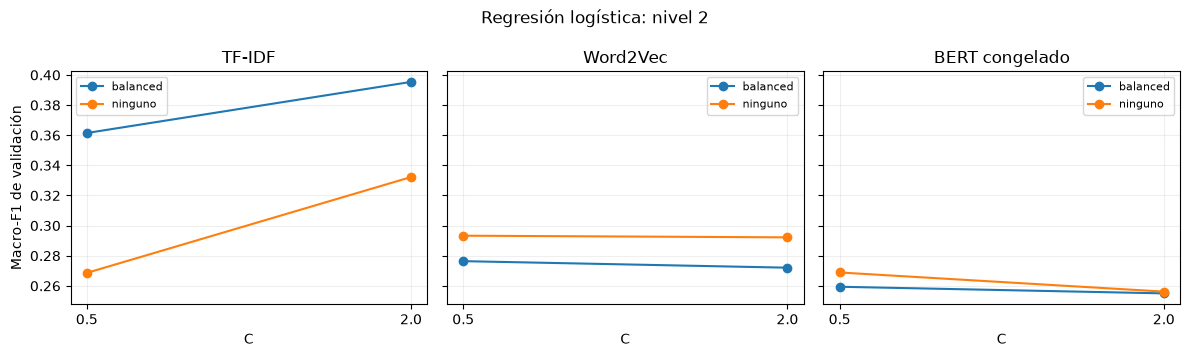

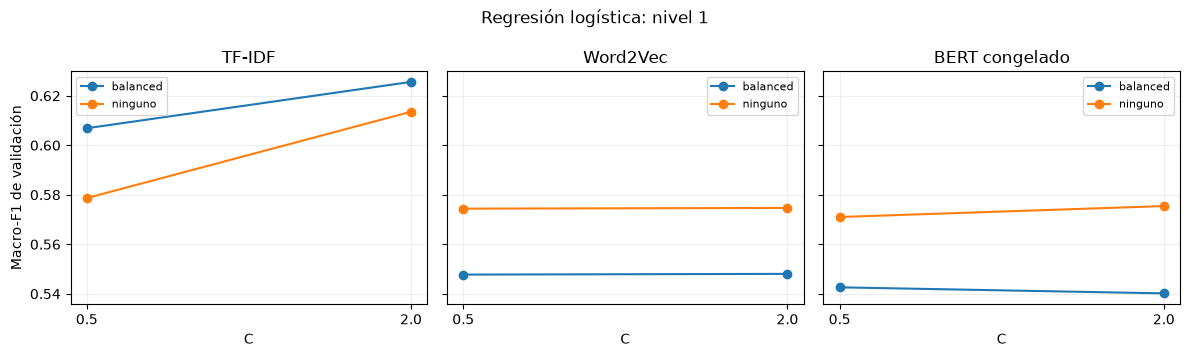

In [6]:
for nivel in (2,1):
    fig, axes = plt.subplots(1,3,figsize=(12,3.6),sharey=True)
    for ax, representacion in zip(axes, ("TF-IDF", "Word2Vec", "BERT congelado")):
        parte = tabla_busqueda[(tabla_busqueda.nivel == nivel) & (tabla_busqueda.representacion == representacion)]
        for peso, grupo in parte.groupby("class_weight"):
            grupo = grupo.sort_values("C")
            ax.plot(grupo.C, grupo.macro_f1, "o-", label=peso)
        ax.set(title=representacion, xlabel="C", xscale="log")
        ax.set_xticks(CS, [str(valor) for valor in CS])
        ax.minorticks_off()
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
    axes[0].set_ylabel("Macro-F1 de validación")
    fig.suptitle(f"Regresión logística: nivel {nivel}")
    fig.tight_layout()
    fig.savefig(FIGURAS / f"izan_validacion_lr_n{nivel}.png", dpi=150, bbox_inches="tight")
    plt.show()


## Red propia de PyTorch sobre Word2Vec

La red tiene una capa oculta ReLU y dropout. Se prueban dos tamaños y tasas de
aprendizaje. Se usa Adam, batch 256, hasta 30 épocas y parada después de cinco
épocas sin mejora en macro-F1 de validación. Se conserva el estado de la mejor
época. La pérdida pondera inversamente la frecuencia de cada clase de train.

Se aprende el escalado con train y se convierten los códigos a índices
consecutivos. El mapeo se invierte para guardar códigos EuroSciVoc reales.
Esta red se implementa en PyTorch, no con MLPClassifier. Se repite en nivel 1
para disponer del mismo control de granularidad.


In [7]:
CONFIGS_RED = [
    dict(ocultas=128, dropout=0.2, lr=0.001),
    dict(ocultas=256, dropout=0.3, lr=0.0005),
]
MAX_EPOCAS, PACIENCIA, BATCH = 30, 5, 256

class RedWord2Vec(torch.nn.Module):
    def __init__(self, entrada, salida, ocultas, dropout):
        super().__init__()
        self.capas = torch.nn.Sequential(
            torch.nn.Linear(entrada, ocultas), torch.nn.ReLU(),
            torch.nn.Dropout(dropout), torch.nn.Linear(ocultas, salida),
        )
    def forward(self, x):
        return self.capas(x)

def predecir_red(red, X, codificador):
    red.eval()
    indices = []
    with torch.no_grad():
        for comienzo in range(0, len(X), 1024):
            indices.extend(red(torch.from_numpy(X[comienzo:comienzo+1024])).argmax(1).numpy())
    return codificador.inverse_transform(np.asarray(indices, dtype=int))

def ajustar_red(nivel):
    nombre = f"izan_mlp_word2vec_n{nivel}"
    ruta = MODELOS / f"{nombre}.joblib"
    ruta_pesos = MODELOS / f"{nombre}.pt"
    firma = dict(**firma_base, features=HASHES_REPRESENTACIONES["word2vec"], nivel=nivel,
                 configs=CONFIGS_RED, epocas=MAX_EPOCAS, paciencia=PACIENCIA, batch=BATCH,
                 perdida="entropía cruzada ponderada inversa frecuencia train")
    if ruta.exists() and ruta_pesos.exists() and not FORZAR_ENTRENAMIENTO:
        previo = joblib.load(ruta)
        if previo["firma"] == firma:
            config = previo["configuracion"]
            red = RedWord2Vec(300, len(previo["codificador"].classes_), config["ocultas"], config["dropout"])
            red.load_state_dict(torch.load(ruta_pesos, map_location="cpu", weights_only=True))
            previo["red"] = red
            print("Red recuperada:", nombre, flush=True)
            return previo

    columna = f"label_nivel{nivel}"
    codificador = LabelEncoder().fit(conjuntos["train"][columna])
    y_train = codificador.transform(conjuntos["train"][columna])
    y_val = codificador.transform(conjuntos["val"][columna])
    escala = StandardScaler().fit(representaciones["word2vec"]["train"])
    X_train = escala.transform(representaciones["word2vec"]["train"]).astype(np.float32)
    X_val = escala.transform(representaciones["word2vec"]["val"]).astype(np.float32)
    frecuencias = np.bincount(y_train, minlength=len(codificador.classes_))
    pesos = torch.tensor(len(y_train)/(len(frecuencias)*frecuencias), dtype=torch.float32)
    criterio = torch.nn.CrossEntropyLoss(weight=pesos)
    datos = torch.utils.data.TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train).long())
    mejor_global, resumen_busqueda = None, []
    for indice, config in enumerate(CONFIGS_RED):
        torch.manual_seed(SEMILLA)
        generador = torch.Generator().manual_seed(SEMILLA)
        lotes = torch.utils.data.DataLoader(datos, batch_size=BATCH, shuffle=True, generator=generador, num_workers=0)
        red = RedWord2Vec(X_train.shape[1], len(codificador.classes_), config["ocultas"], config["dropout"])
        optimizador = torch.optim.Adam(red.parameters(), lr=config["lr"])
        mejor_f1, sin_mejora, mejor_epoca = -1, 0, 0
        historial, mejor_estado = [], None
        inicio = time.perf_counter()
        for epoca in range(1, MAX_EPOCAS+1):
            red.train()
            suma_loss, suma_pesos = 0.0, 0.0
            for X_lote, y_lote in lotes:
                optimizador.zero_grad()
                loss = criterio(red(X_lote), y_lote)
                loss.backward()
                optimizador.step()
                peso_lote = pesos[y_lote].sum().item()
                suma_loss += loss.item()*peso_lote
                suma_pesos += peso_lote
            red.eval()
            with torch.no_grad():
                logits = red(torch.from_numpy(X_val))
                val_loss = criterio(logits, torch.from_numpy(y_val).long()).item()
                pred = codificador.inverse_transform(logits.argmax(1).numpy())
            metricas = evaluar(conjuntos["val"][columna], pred, clases=clases_nivel[nivel])
            historial.append(dict(epoca=epoca, train_loss=suma_loss/suma_pesos, val_loss=val_loss, **metricas))
            print(nombre, "config", indice, "época", epoca, "F1", round(metricas["macro_f1"],4), flush=True)
            if metricas["macro_f1"] > mejor_f1:
                mejor_f1, mejor_epoca, sin_mejora = metricas["macro_f1"], epoca, 0
                mejor_estado = copy.deepcopy(red.state_dict())
            else:
                sin_mejora += 1
            if sin_mejora >= PACIENCIA:
                break
        historial_df = pd.DataFrame(historial)
        historial_df.to_csv(RESULTADOS / f"{nombre}_config{indice}_historial.csv", index=False)
        resumen = dict(experimento=nombre, nivel=nivel, config=indice, **config,
                       mejor_epoca=mejor_epoca, macro_f1=mejor_f1,
                       segundos=round(time.perf_counter()-inicio,2))
        resumen_busqueda.append(resumen)
        if mejor_global is None or mejor_f1 > mejor_global["metricas"]["macro_f1"]:
            red.load_state_dict(mejor_estado)
            pred = predecir_red(red, X_val, codificador)
            mejor_global = dict(
                estado=copy.deepcopy(mejor_estado), configuracion=resumen,
                metricas=evaluar(conjuntos["val"][columna], pred, clases=clases_nivel[nivel]),
                historial=historial_df,
            )
    torch.save(mejor_global.pop("estado"), ruta_pesos)
    mejor_global.update(
        nombre=nombre, tipo="mlp", nivel=nivel, representacion="Word2Vec", firma=firma,
        escala=escala, codificador=codificador, busqueda=resumen_busqueda,
    )
    joblib.dump(mejor_global, ruta, compress=3)
    config = mejor_global["configuracion"]
    red = RedWord2Vec(300, len(codificador.classes_), config["ocultas"], config["dropout"])
    red.load_state_dict(torch.load(ruta_pesos, map_location="cpu", weights_only=True))
    mejor_global["red"] = red
    return mejor_global


Red recuperada: izan_mlp_word2vec_n2


izan_mlp_word2vec_n2 val {'accuracy': 0.4074421513445904, 'macro_f1': 0.31438849958259074} predicciones: izan_mlp_word2vec_n2_val.csv


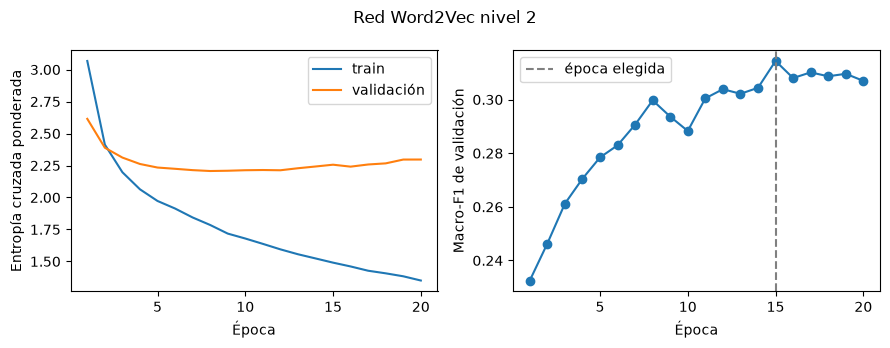

Red recuperada: izan_mlp_word2vec_n1


izan_mlp_word2vec_n1 val {'accuracy': 0.6165311653116531, 'macro_f1': 0.5765621972678016} predicciones: izan_mlp_word2vec_n1_val.csv


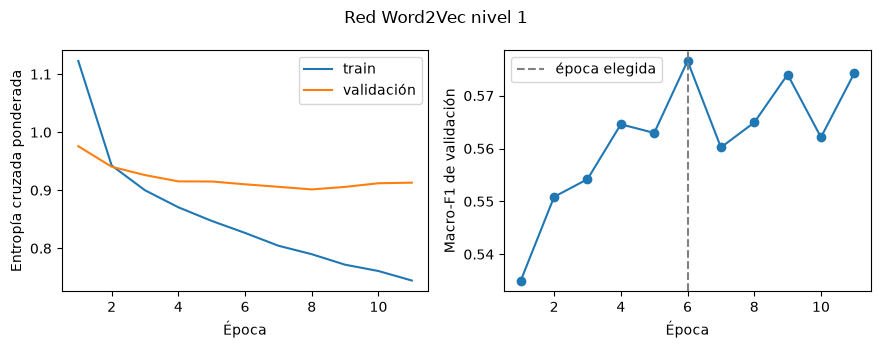

In [8]:
busqueda_red = []
for nivel in (2,1):
    resultado = ajustar_red(nivel)
    nombre = resultado["nombre"]
    seleccionados[nombre] = resultado
    busqueda_red.extend(resultado["busqueda"])
    X_val = resultado["escala"].transform(representaciones["word2vec"]["val"]).astype(np.float32)
    pred = predecir_red(resultado["red"], X_val, resultado["codificador"])
    registrar_predicciones(nombre, "Word2Vec", "Red propia PyTorch", nivel, "val", pred)
    historial = resultado["historial"]
    fig, axes = plt.subplots(1,2,figsize=(9,3.5))
    axes[0].plot(historial.epoca, historial.train_loss, label="train")
    axes[0].plot(historial.epoca, historial.val_loss, label="validación")
    axes[0].set(xlabel="Época", ylabel="Entropía cruzada ponderada")
    axes[0].legend()
    axes[1].plot(historial.epoca, historial.macro_f1, "o-")
    axes[1].axvline(resultado["configuracion"]["mejor_epoca"], color="grey", linestyle="--", label="época elegida")
    axes[1].set(xlabel="Época", ylabel="Macro-F1 de validación")
    axes[1].legend()
    fig.suptitle(f"Red Word2Vec nivel {nivel}")
    fig.tight_layout()
    fig.savefig(FIGURAS / f"izan_mlp_word2vec_n{nivel}_curvas.png", dpi=150, bbox_inches="tight")
    plt.show()
pd.DataFrame(busqueda_red).to_csv(RESULTADOS / "busqueda_red_izan.csv", index=False)


## Extensión con metadatos

Se comparan regresión logística con TF-IDF, solo metadatos y ambos concatenados.
Se fija TF-IDF como representación de texto de esta extensión para aislar su
aportación sin introducir otra selección de modelos. Se reutiliza su búsqueda
anterior y se aplica la misma búsqueda a metadatos y combinación.

Las variables son logaritmo de coste y contribución UE, duración, número de países
participantes y país coordinador. No se utilizan identificadores, EuroSciVoc,
etiquetas, títulos de temas o campos que reproduzcan el objetivo. Los ausentes
numéricos se imputan con la mediana de train, el país con una categoría fija;
la codificación y el escalado se aprenden también solo con train.


In [9]:
def preparar_metadatos(parte):
    salida = pd.DataFrame(index=parte.index)
    for original, nombre in (("totalCost", "log_coste"), ("ecMaxContribution", "log_financiacion_ue")):
        valores = pd.to_numeric(parte[original], errors="coerce")
        salida[nombre] = np.log1p(valores.where(valores >= 0))
    duracion = (parte["endDate"]-parte["startDate"]).dt.days.astype(float)
    salida["duracion_dias"] = duracion.where(duracion >= 0)
    def contar_paises(valor):
        if not isinstance(valor,str) or not valor.strip():
            return np.nan
        paises = {trozo.split("|",1)[0] for trozo in valor.split() if "|" in trozo}
        return len(paises) if paises else np.nan
    salida["num_paises"] = parte["countryContr"].map(contar_paises)
    salida["pais_coordinador"] = parte["coordinatorCountry"].fillna("desconocido").astype(str)
    return salida

metadatos = {nombre: preparar_metadatos(parte) for nombre, parte in conjuntos.items()}
huellas_meta = {
    nombre: hashlib.sha256(parte.to_csv(index=False, lineterminator="\n").encode("utf-8")).hexdigest()
    for nombre, parte in metadatos.items() if nombre in ("train", "val")
}
numericas = ["log_coste", "log_financiacion_ue", "duracion_dias", "num_paises"]
preprocesador_meta = ColumnTransformer([
    ("numericas", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]), numericas),
    ("pais", OneHotEncoder(handle_unknown="ignore"), ["pais_coordinador"]),
], sparse_threshold=1.0)
matrices_meta = {"train": sparse.csr_matrix(preprocesador_meta.fit_transform(metadatos["train"]))}
for conjunto in ("val", "test"):
    matrices_meta[conjunto] = sparse.csr_matrix(preprocesador_meta.transform(metadatos[conjunto]))
matrices_combinadas = {
    k: sparse.hstack([representaciones["tfidf"][k], matrices_meta[k]], format="csr")
    for k in conjuntos
}
joblib.dump(preprocesador_meta, MODELOS / "preprocesador_metadatos.joblib", compress=3)
print("Metadatos:", {k: v.shape for k,v in matrices_meta.items()})

for clave, representacion, matrices in (
    ("metadatos", "Metadatos", matrices_meta),
    ("tfidf_metadatos", "TF-IDF + metadatos", matrices_combinadas),
):
    firma = dict(tfidf=HASHES_REPRESENTACIONES["tfidf"] if clave == "tfidf_metadatos" else None,
                 columnas=list(metadatos["train"].columns), datos_metadatos=huellas_meta,
                 transformaciones="log1p costes, mediana y StandardScaler train, OHE país")
    nombre = f"izan_lr_{clave}_n2"
    resultado = ajustar_lr(nombre, representacion, 2, matrices["train"], matrices["val"], False, firma)
    resultado["clave_features"] = clave
    seleccionados[nombre] = resultado
    registrar_predicciones(nombre, representacion, "Regresión logística", 2, "val", resultado["modelo"].predict(matrices["val"]))

tabla_busqueda = pd.DataFrame(busquedas)
tabla_busqueda.to_csv(RESULTADOS / "busqueda_lr_izan.csv", index=False)


Metadatos: {'train': (19189, 56), 'val': (9594, 56), 'test': (3199, 56)}
Modelo recuperado: izan_lr_metadatos_n2


izan_lr_metadatos_n2 val {'accuracy': 0.13466750052115906, 'macro_f1': 0.02461324060012693} predicciones: izan_lr_metadatos_n2_val.csv


Modelo recuperado: izan_lr_tfidf_metadatos_n2


izan_lr_tfidf_metadatos_n2 val {'accuracy': 0.4863456326870961, 'macro_f1': 0.3728504979547791} predicciones: izan_lr_tfidf_metadatos_n2_val.csv


## Resultados que recibe Sara

Cada configuración elegida genera una fila en metricas_izan.csv y un CSV de
predicciones con projectID, nivel, conjunto, y_real e y_pred. La métrica elegida
es la de validación; no es todavía una estimación final libre de selección.
El cuaderno 03 puede leer estos archivos sin cambiar sus funciones de carga.


,experimento,representacion,modelo,nivel,conjunto,accuracy,macro_f1
0,izan_lr_tfidf_n2,TF-IDF,Regresión logística,2,val,0.4908,0.3954
9,izan_lr_tfidf_metadatos_n2,TF-IDF + metadatos,Regresión logística,2,val,0.4863,0.3729
6,izan_mlp_word2vec_n2,Word2Vec,Red propia PyTorch,2,val,0.4074,0.3144
1,izan_lr_word2vec_n2,Word2Vec,Regresión logística,2,val,0.4437,0.2933
2,izan_lr_bert_n2,BERT congelado,Regresión logística,2,val,0.4081,0.2689
8,izan_lr_metadatos_n2,Metadatos,Regresión logística,2,val,0.1347,0.0246
3,izan_lr_tfidf_n1,TF-IDF,Regresión logística,1,val,0.6650,0.6256
7,izan_mlp_word2vec_n1,Word2Vec,Red propia PyTorch,1,val,0.6165,0.5766
5,izan_lr_bert_n1,BERT congelado,Regresión logística,1,val,0.6357,0.5754
4,izan_lr_word2vec_n1,Word2Vec,Regresión logística,1,val,0.6369,0.5747


,macro_f1_nivel1,macro_f1_nivel2
representacion,,
BERT congelado,0.5754,0.2689
TF-IDF,0.6256,0.3954
Word2Vec,0.5747,0.2933


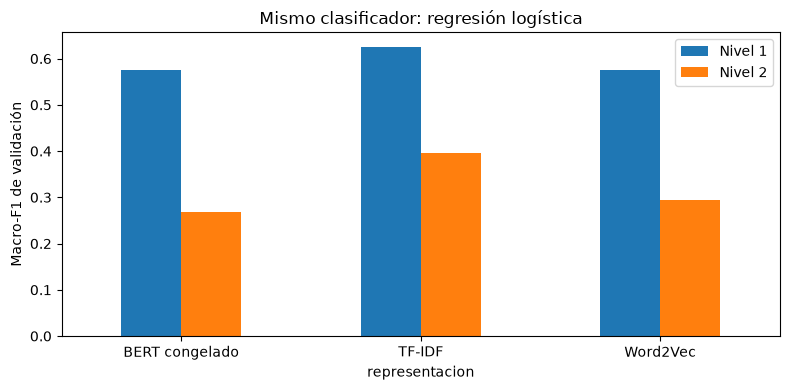

,representacion,accuracy,macro_f1
0,TF-IDF,0.4908,0.3954
8,Metadatos,0.1347,0.0246
9,TF-IDF + metadatos,0.4863,0.3729


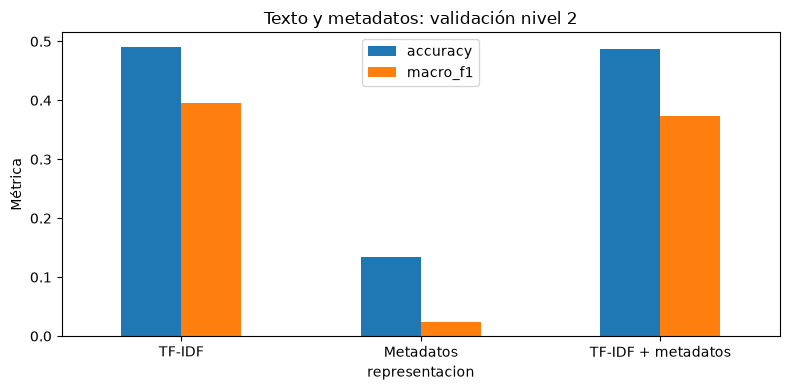

In [10]:
metricas_izan = pd.read_csv(RESULTADOS / ARCHIVO_METRICAS)
actuales = metricas_izan[(metricas_izan.conjunto == "val") & metricas_izan.experimento.isin(seleccionados)]
display(actuales.sort_values(["nivel","macro_f1"],ascending=[False,False]).round(4))

selecciones_json = {
    nombre: dict(nivel=r["nivel"], representacion=r["representacion"], tipo=r["tipo"], configuracion=r["configuracion"])
    for nombre, r in seleccionados.items()
}
(RESULTADOS / "configuraciones_izan.json").write_text(
    json.dumps(dict(semilla=SEMILLA, version=VERSION_EXPERIMENTOS,
                    criterio="máximo macro-F1 de validación; test no usado",
                    huellas_datos=FIRMA_DATOS, hash_representaciones=HASHES_REPRESENTACIONES,
                    modelos=selecciones_json), ensure_ascii=False, indent=2), encoding="utf-8"
)

solo_lr = actuales[actuales.experimento.str.match(r"izan_lr_(tfidf|word2vec|bert)_n[12]$")]
ranking = solo_lr.pivot(index="representacion", columns="nivel", values="macro_f1")
ranking.columns = [f"macro_f1_nivel{n}" for n in ranking.columns]
ranking.to_csv(RESULTADOS / "ranking_representaciones_izan_val.csv")
display(ranking.round(4))
ax = ranking.plot.bar(figsize=(8,4), rot=0)
ax.set(ylabel="Macro-F1 de validación", title="Mismo clasificador: regresión logística")
ax.legend(["Nivel 1", "Nivel 2"])
plt.tight_layout()
plt.savefig(FIGURAS / "izan_comparacion_representaciones_val.png", dpi=150, bbox_inches="tight")
plt.show()

experimentos_extension = ["izan_lr_tfidf_n2", "izan_lr_metadatos_n2", "izan_lr_tfidf_metadatos_n2"]
extension = actuales[actuales.experimento.isin(experimentos_extension)].copy()
extension.to_csv(RESULTADOS / "extension_izan_val.csv", index=False)
display(extension[["representacion", "accuracy", "macro_f1"]].round(4))
ax = extension.set_index("representacion")[["accuracy", "macro_f1"]].plot.bar(figsize=(8,4), rot=0)
ax.set(title="Texto y metadatos: validación nivel 2", ylabel="Métrica")
plt.tight_layout()
plt.savefig(FIGURAS / "izan_extension_val.png", dpi=150, bbox_inches="tight")
plt.show()


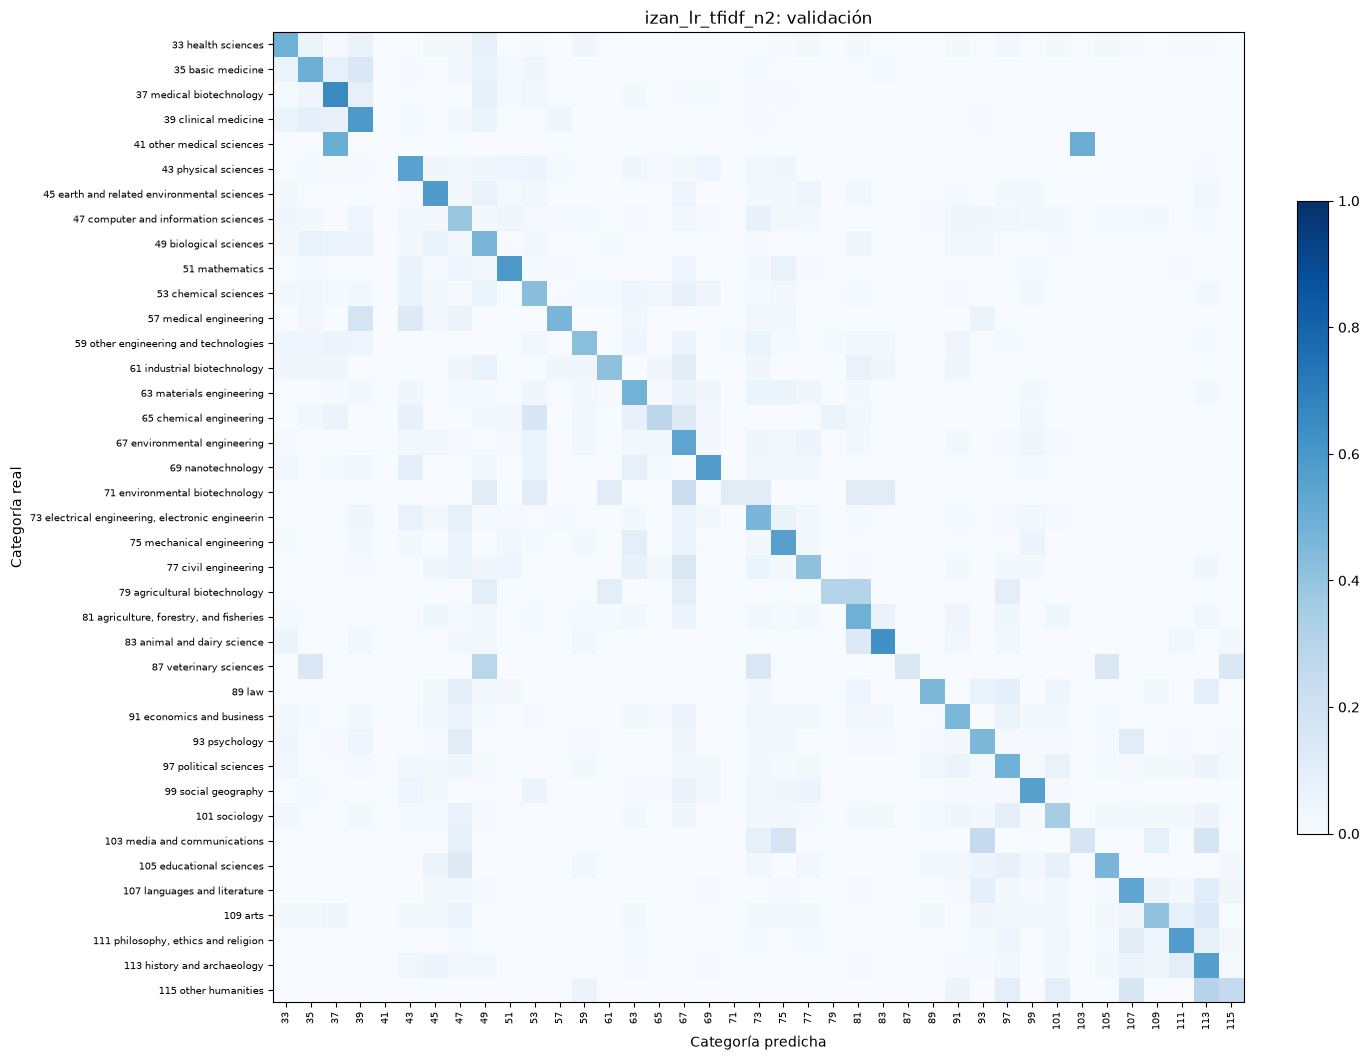

Mejor configuración básica de Izan por macro-F1 de validación: izan_lr_tfidf_n2


In [11]:
basicos_n2 = actuales[(actuales.nivel == 2) & ~actuales.experimento.isin(experimentos_extension[1:])]
mejor_nombre = basicos_n2.sort_values("macro_f1", ascending=False).iloc[0].experimento
tabla_pred = pd.read_csv(RESULTADOS / "predicciones" / f"{mejor_nombre}_val.csv")
clases = clases_nivel[2]
catalogo = scivoc.dropna(subset=["code"])
nombres_categoria = dict(zip(catalogo.code.astype(int), catalogo.title))
matriz = confusion_matrix(tabla_pred.y_real, tabla_pred.y_pred, labels=clases, normalize="true")
fig, ax = plt.subplots(figsize=(13,11))
imagen = ax.imshow(matriz, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(clases)), [str(c) for c in clases], rotation=90, fontsize=7)
ax.set_yticks(range(len(clases)), [f"{c} {nombres_categoria.get(c,'')}"[:48] for c in clases], fontsize=7)
ax.set(xlabel="Categoría predicha", ylabel="Categoría real", title=f"{mejor_nombre}: validación")
fig.colorbar(imagen, ax=ax, fraction=0.03)
fig.tight_layout()
fig.savefig(FIGURAS / "izan_confusion_mejor_n2_val.png", dpi=150, bbox_inches="tight")
plt.show()
print("Mejor configuración básica de Izan por macro-F1 de validación:", mejor_nombre)


## Test final desactivado

Se activa EVALUAR_TEST cuando el grupo haya cerrado las decisiones de modelado.
Este bloque no busca parámetros ni decide ganadores por el test. Reutiliza los
modelos ya elegidos con validación. Sara puede compararlos con sus propios
resultados de test cuando los haya generado.


In [12]:
if EVALUAR_TEST:
    for nombre, resultado in seleccionados.items():
        if resultado["tipo"] == "mlp":
            X = resultado["escala"].transform(representaciones["word2vec"]["test"]).astype(np.float32)
            pred = predecir_red(resultado["red"], X, resultado["codificador"])
            modelo = "Red propia PyTorch"
        else:
            clave = resultado["clave_features"]
            if clave == "metadatos":
                X = matrices_meta["test"]
            elif clave == "tfidf_metadatos":
                X = matrices_combinadas["test"]
            else:
                X = representaciones[clave]["test"]
            pred = resultado["modelo"].predict(X)
            modelo = "Regresión logística"
        registrar_predicciones(nombre, resultado["representacion"], modelo, resultado["nivel"], "test", pred)
else:
    print("Test pendiente. Los archivos entregados ahora corresponden a validación.")


Test pendiente. Los archivos entregados ahora corresponden a validación.


## Para interpretar y repetir

- La búsqueda es pequeña y la misma validación se usa para elegir parámetros y
  época. Las métricas de los ganadores pueden ser optimistas; la evaluación final
  será en test, sin volver a ajustar después de mirarlo.
- Los resultados por clase están guardados aunque algunas clases pequeñas no se
  predigan. Sara puede aplicar su comparación pareada a los CSV de predicciones.
- El ranking de las tres representaciones se calcula solo con regresión logística
  para mantener el mismo clasificador. La red y la extensión se comparan aparte.
- Los modelos y matrices grandes permanecen en datos/cache y no se suben a GitHub.
  Las versiones efectivas están en resultados/entorno_izan.json. Los parámetros y
  las búsquedas quedan también guardados.
- Si cambia el código de los experimentos, actualizar VERSION_EXPERIMENTOS o
  activar FORZAR_ENTRENAMIENTO. Las cachés de modelos también se invalidan cuando
  cambian parámetros, entorno, datos o la representación utilizada.
- La generación de TF-IDF y Word2Vec reproduce la base de Mónica; los resultados de
  BERT congelado parten de la caché de Sara. No se ha repetido su fine-tuning.
